# L16 worked example: generative models as solvers, Gaussian mixtures and flow matching

Every model so far in the course learned one direction, from inputs to an output. Here you
learn the **joint** distribution of inputs and outputs from data, then **condition** it on
the output you want and sample the inputs that give it. Each problem has a known answer, so
every sample can be checked:

1. $y = |x|$ with the middle of the data removed. Which $x$ gives $y = 0.75$?
2. The Peng-Robinson equation of state for propane at 300 K and 10 bar. Which
   compressibility factors $Z$ make the cubic residual zero?
3. Consecutive reactions $A \to B \to C$ in a batch reactor. Which residence time
   maximizes $C_B$?

Adapted from Alves & Kitchin, "Generative machine learning approaches to optimization"
(ChemRxiv, 2026, doi:10.26434/chemrxiv-2025-hk886/v3) and its repository,
https://github.com/KitchinHUB/generative-optimization. Everything runs on a CPU in a few
minutes.

## Run this first on Colab

Colab starts from its own preinstalled environment rather than this course's `uv`
environment, so run the cell below before anything else. It installs what this
notebook needs and Colab does not already have. Outside Colab it does nothing, so
you can run it or skip it.


In [ ]:
# Run this first on Colab. Anywhere else this cell does nothing.
#
# Only genuinely missing packages are installed, so Colab's own versions of
# everything it already ships are left alone.
import importlib.util
import subprocess
import sys

REQUIREMENTS = {
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "sklearn": "scikit-learn",
    "torch": "torch",
}


def _missing(module):
    try:
        return importlib.util.find_spec(module) is None
    except ModuleNotFoundError:  # the parent package is absent
        return True


if "google.colab" in sys.modules:
    need = sorted({pip for mod, pip in REQUIREMENTS.items() if _missing(mod)})
    if need:
        print("installing:", " ".join(need))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    print("Colab setup done." if need else "Colab: nothing to install.")


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.mixture import GaussianMixture

rng = np.random.default_rng(16)
torch.manual_seed(0)

## 1. An inverse question with two answers

The data are $y = |x|$ plus a little noise, with nothing in $-0.5 < x < 0.5$, the situation
in Figure 2 of the paper. First the approach from L9: fit a model of $x$ as a function of $y$
and ask it.

In [3]:
x = rng.uniform(-1.2, 1.2, 960)
x = x[np.abs(x) >= 0.5][:240]
y = np.abs(x) + 0.03 * rng.standard_normal(x.size)

b, a = np.polyfit(y, x, 1)
print(f"least-squares x = {a:.3f} + {b:.3f} y  ->  at y = 0.75, x = {a + b * 0.75:+.3f}")
print("the true answers are -0.75 and +0.75")

least-squares x = -0.078 + 0.110 y  ->  at y = 0.75, x = +0.005
the true answers are -0.75 and +0.75


The fit predicts a value near zero, the average of the two answers. It is not either answer,
and there is no data anywhere near it. A more flexible regressor (a GP, a neural network)
does the same thing, because minimizing squared error over data with two branches puts the
prediction at their mean. Asking for one number when there are two answers is the mistake.

## 2. Learn the joint distribution with a Gaussian mixture

Fit $p(x, y)$ with $K$ Gaussian components by expectation maximization, for several $K$,
and let BIC choose.

In [4]:
D = np.c_[x, y]
for K in range(1, 7):
    g = GaussianMixture(K, covariance_type="full", n_init=5, random_state=0).fit(D)
    print(f"K = {K}: BIC = {g.bic(D):8.1f}")
gmm = GaussianMixture(2, covariance_type="full", n_init=5, random_state=0).fit(D)

K = 1: BIC =    542.6


K = 2: BIC =   -697.1
K = 3: BIC =   -686.9


K = 4: BIC =   -672.8


K = 5: BIC =   -652.2


K = 6: BIC =   -628.9


### Conditioning, written out

For one Gaussian with blocks $\mu = (\mu_u, \mu_k)$ and
$\Sigma = \begin{pmatrix}\Sigma_{uu} & \Sigma_{uk} \\ \Sigma_{ku} & \Sigma_{kk}\end{pmatrix}$,
where $k$ are the coordinates you fix and $u$ the ones you want, the conditional is Gaussian
with

$$\mu_{u|k} = \mu_u + \Sigma_{uk}\Sigma_{kk}^{-1}(v - \mu_k), \qquad
\Sigma_{u|k} = \Sigma_{uu} - \Sigma_{uk}\Sigma_{kk}^{-1}\Sigma_{ku}.$$

For a mixture, condition every component and reweight each one by the density it gives the
fixed values, $\pi_j\,\mathcal{N}(v; \mu_{k,j}, \Sigma_{kk,j})$. The function below is the
whole method. Notice that which columns are "known" is an argument: the split between inputs
and outputs is chosen after training.

In [5]:
def condition(gmm, known, values, n=4000, seed=0):
    """Sample p(unknown columns | known columns = values) from a fitted GaussianMixture."""
    r = np.random.default_rng(seed)
    d = gmm.means_.shape[1]
    un = [j for j in range(d) if j not in known]
    v = np.atleast_1d(np.asarray(values, float))
    logw, means, covs = [], [], []
    for w, m, S in zip(gmm.weights_, gmm.means_, gmm.covariances_):
        Skk, Suk, Suu = S[np.ix_(known, known)], S[np.ix_(un, known)], S[np.ix_(un, un)]
        sol = np.linalg.solve(Skk, v - m[known])
        means.append(m[un] + Suk @ sol)
        covs.append(Suu - Suk @ np.linalg.solve(Skk, Suk.T))
        logw.append(np.log(w) - 0.5 * (v - m[known]) @ sol - 0.5 * np.linalg.slogdet(2 * np.pi * Skk)[1])
    logw = np.array(logw)
    w = np.exp(logw - logw.max())
    w /= w.sum()
    ks = r.choice(len(w), size=n, p=w)
    return np.array([r.multivariate_normal(means[k], covs[k]) for k in ks])


xs = condition(gmm, known=[1], values=[0.75])[:, 0]
print(f"p(x | y = 0.75): {np.mean(xs < 0):.0%} of samples at x < 0, "
      f"means {xs[xs < 0].mean():+.3f} and {xs[xs > 0].mean():+.3f}")

ys = condition(gmm, known=[0], values=[0.9])[:, 0]
print(f"the same model, forward: p(y | x = 0.9) has mean {ys.mean():.3f} (|0.9| = 0.9)")

p(x | y = 0.75): 49% of samples at x < 0, means -0.754 and +0.753


the same model, forward: p(y | x = 0.9) has mean 0.899 (|0.9| = 0.9)


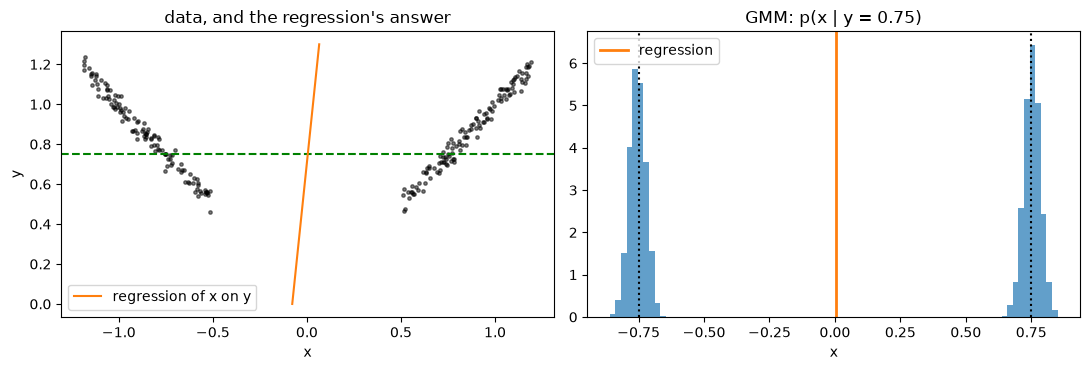

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.scatter(x, y, s=6, color="k", alpha=0.5)
a1.axhline(0.75, color="g", ls="--")
a1.plot(a + b * np.array([0, 1.3]), [0, 1.3], color="C1", label="regression of x on y")
a1.set(xlabel="x", ylabel="y", title="data, and the regression's answer")
a1.legend()
a2.hist(xs, bins=80, density=True, alpha=0.7)
a2.axvline(a + b * 0.75, color="C1", lw=2, label="regression")
for v in (-0.75, 0.75):
    a2.axvline(v, color="k", ls=":")
a2.set(xlabel="x", title="GMM: p(x | y = 0.75)")
a2.legend()
plt.tight_layout()

## 3. Transform noise into data with conditional flow matching

The second approach never writes down a density. It learns a velocity field
$v_\theta(x, c, t)$ that carries a sample of $\mathcal{N}(0, 1)$ at $t = 0$ to a sample of
$p(x \mid c)$ at $t = 1$. Training is regression: pick a data pair $(x_1, c)$, a noise
sample $x_0$ and a time $t$, form the point $x_t = (1 - t)x_0 + t x_1$ on the straight line
between them, and fit $v_\theta(x_t, c, t)$ to the line's velocity $x_1 - x_0$ by mean
squared error. Sampling integrates $dx/dt = v_\theta$ from $t = 0$ to 1.

The columns are standardized first, as in the paper, so the network sees numbers of order
one. The paper's network uses sigmoid activations and 500 epochs of training; this one uses
SiLU and 4,000 minibatches, which is enough here and runs in seconds.

In [7]:
class CFM:
    """Conditional flow matching for x given c, both standardized internally."""

    def __init__(self, X, C, steps=4000, seed=0):
        torch.manual_seed(seed)
        self.mx, self.sx = X.mean(0), X.std(0)
        self.mc, self.sc = C.mean(0), C.std(0)
        Xn = torch.tensor((X - self.mx) / self.sx, dtype=torch.float32)
        Cn = torch.tensor((C - self.mc) / self.sc, dtype=torch.float32)
        dx, dc = Xn.shape[1], Cn.shape[1]
        self.net = torch.nn.Sequential(
            torch.nn.Linear(dx + dc + 1, 64), torch.nn.SiLU(),
            torch.nn.Linear(64, 64), torch.nn.SiLU(),
            torch.nn.Linear(64, 64), torch.nn.SiLU(),
            torch.nn.Linear(64, dx))
        opt = torch.optim.Adam(self.net.parameters(), 1e-3)
        for _ in range(steps):
            i = torch.randint(0, len(Xn), (256,))
            x1, c = Xn[i], Cn[i]
            x0 = torch.randn_like(x1)
            t = torch.rand(len(i), 1)
            xt = (1 - t) * x0 + t * x1
            loss = ((self.net(torch.cat([xt, c, t], 1)) - (x1 - x0)) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()

    def sample(self, c, n=2000, steps=100, seed=1, path=False):
        g = torch.Generator().manual_seed(seed)
        cn = torch.tensor((np.atleast_1d(c) - self.mc) / self.sc, dtype=torch.float32).expand(n, -1)
        z = torch.randn(n, len(self.mx), generator=g)
        traj = [z]
        with torch.no_grad():
            for k in range(steps):
                t = torch.full((n, 1), k / steps)
                z = z + self.net(torch.cat([z, cn, t], 1)) / steps
                traj.append(z)
        out = np.array([q.numpy() for q in traj]) * self.sx + self.mx
        return out if path else out[-1]


fm = CFM(x[:, None], y[:, None])
xf = fm.sample([0.75])[:, 0]
print(f"flow matching p(x | y = 0.75): {np.mean(xf < 0):.0%} at x < 0, "
      f"means {xf[xf < 0].mean():+.3f} and {xf[xf > 0].mean():+.3f}")

flow matching p(x | y = 0.75): 47% at x < 0, means -0.736 and +0.759


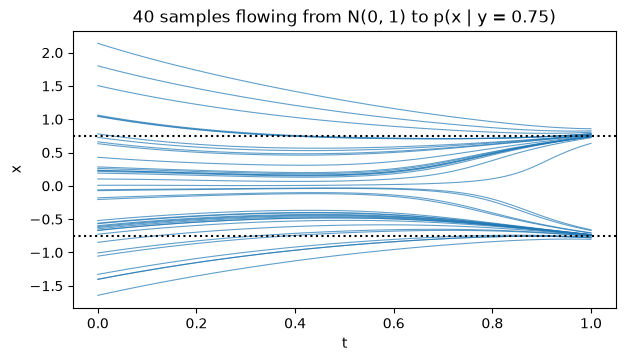

In [8]:
P = fm.sample([0.75], n=40, path=True)[:, :, 0]
plt.figure(figsize=(7, 3.6))
plt.plot(np.linspace(0, 1, P.shape[0]), P, color="C0", lw=0.8, alpha=0.7)
for v in (-0.75, 0.75):
    plt.axhline(v, color="k", ls=":")
plt.xlabel("t")
plt.ylabel("x")
plt.title("40 samples flowing from N(0, 1) to p(x | y = 0.75)");

### Asking about the gap

There is no data with $y < 0.5$. Ask both models for $p(x \mid y = 0.3)$, whose true answers
are $\pm 0.3$, and compare. Neither model has seen anything like it, and both still answer,
with no warning. Whatever they say comes from their building blocks, not from data.

In [9]:
xg = condition(gmm, known=[1], values=[0.3])[:, 0]
xfg = fm.sample([0.3])[:, 0]
for name, s in (("GMM", xg), ("flow matching", xfg)):
    print(f"{name:14s} p(x | y = 0.3): means {s[s < 0].mean():+.3f} / {s[s > 0].mean():+.3f} (truth -0.3 / +0.3)")

GMM            p(x | y = 0.3): means -0.305 / +0.312 (truth -0.3 / +0.3)
flow matching  p(x | y = 0.3): means -0.407 / +0.334 (truth -0.3 / +0.3)


## 4. Root finding: the Peng-Robinson cubic

In compressibility-factor form the Peng-Robinson equation of state is a cubic,
$r(Z) = Z^3 - (1 - B)Z^2 + (A - 3B^2 - 2B)Z - (AB - B^2 - B^3) = 0$. For propane at 300 K and
10 bar it has three real roots: liquid, an unstable middle root, and vapor. Newton's method
finds whichever root its starting guess happens to lead to. The generative approach samples $Z$ uniformly,
evaluates the residual, learns $p(Z, r)$, and conditions on $r = 0$.

In [10]:
R, Tc, Pc, omega = 8.314, 369.8, 42.48e5, 0.152
T, P = 300.0, 10e5
kappa = 0.37464 + 1.54226 * omega - 0.26992 * omega**2
alpha = (1 + kappa * (1 - np.sqrt(T / Tc))) ** 2
A = 0.45724 * R**2 * Tc**2 / Pc * alpha * P / (R * T) ** 2
B = 0.07780 * R * Tc / Pc * P / (R * T)
coef = [1, -(1 - B), A - 3 * B**2 - 2 * B, -(A * B - B**2 - B**3)]
roots = np.sort(np.roots(coef).real)
print("numpy.roots:", np.round(roots, 4))

Z = np.random.default_rng(0).uniform(0.01, 0.99, 2000)
r = np.polyval(coef, Z)

numpy.roots: [0.0348 0.128  0.8147]


In [11]:
def gmm_roots(feature, inverse, K=12):
    X = np.c_[feature, r]
    mu, sd = X.mean(0), X.std(0)
    g = GaussianMixture(K, covariance_type="full", n_init=3, random_state=0).fit((X - mu) / sd)
    s = condition(g, known=[1], values=[(0 - mu[1]) / sd[1]])[:, 0]
    return inverse(s * sd[0] + mu[0])


def report(name, s):
    near = [s[np.abs(s - v) < 0.03] for v in roots]
    print(f"{name:26s}", "  ".join(f"{m.mean():.4f} ({len(m) / len(s):.0%})" for m in near),
          f"  elsewhere {1 - sum(len(m) for m in near) / len(s):.0%}")


s_raw = gmm_roots(Z, lambda v: v)
s_log = gmm_roots(np.log(Z), np.exp)
s_fm = CFM(Z[:, None], r[:, None]).sample([0.0], n=4000)[:, 0]
print("cluster means near each root (share of samples):")
report("GMM on (Z, r)", s_raw)
report("GMM on (log Z, r)", s_log)
report("flow matching on (Z, r)", s_fm)

cluster means near each root (share of samples):
GMM on (Z, r)              0.0440 (63%)  0.1273 (25%)  0.8143 (6%)   elsewhere 7%
GMM on (log Z, r)          0.0346 (32%)  0.1257 (63%)  0.8149 (5%)   elsewhere 0%
flow matching on (Z, r)    0.0391 (20%)  0.1182 (40%)  0.8092 (13%)   elsewhere 27%


All three roots appear in one set of samples, which Newton's method from a single guess
cannot give you. The accuracy depends on how the data represents the problem: the liquid
root sits in a narrow region of $Z$, and fitting in $\log Z$ puts more resolution there. The
flow-matching samples blur the liquid and unstable roots together: between them $|r|$ never
exceeds about 0.002, a few percent of its spread in the data, so the condition "$r = 0$" barely
separates them.

The honest last step is to treat the samples as starting points and polish each cluster with
the real model.

In [12]:
def newton(z, n=20):
    p, dp = np.poly1d(coef), np.poly1d(coef).deriv()
    for _ in range(n):
        z = z - p(z) / dp(z)
    return z


starts = [s_raw[np.abs(s_raw - v) < 0.03].mean() for v in roots]
print("GMM cluster means :", np.round(starts, 4))
print("after Newton      :", np.round([newton(z) for z in starts], 4))
print("numpy.roots       :", np.round(roots, 4))

GMM cluster means : [0.044  0.1273 0.8143]
after Newton      : [0.0348 0.128  0.8147]
numpy.roots       : [0.0348 0.128  0.8147]


## 5. Optimization: condition on the derivative being zero

For $A \to B \to C$ with $k_1 = 0.5$ and $k_2 = 0.2\ \mathrm{min}^{-1}$ and
$C_{A0} = 1$ mol/L, the intermediate is
$C_B(\tau) = \frac{C_{A0}k_1}{k_2 - k_1}(e^{-k_1\tau} - e^{-k_2\tau})$, with its maximum at
$\tau^* = \ln(k_1/k_2)/(k_1 - k_2) \approx 3.05$ min. Learn $p(\tau, dC_B/d\tau)$ and
condition on the derivative being zero. The derivative comes from automatic differentiation,
as in L11, so the recipe works for any differentiable model.

In [13]:
k1, k2, CA0 = 0.5, 0.2, 1.0
tau = torch.tensor(np.random.default_rng(1).uniform(0, 20, 2000), requires_grad=True)
CB = CA0 * k1 / (k2 - k1) * (torch.exp(-k1 * tau) - torch.exp(-k2 * tau))
(dCB,) = torch.autograd.grad(CB.sum(), tau)
X = np.c_[tau.detach().numpy(), dCB.numpy()]

mu, sd = X.mean(0), X.std(0)
g = GaussianMixture(8, covariance_type="full", n_init=3, random_state=0).fit((X - mu) / sd)
ts = condition(g, known=[1], values=[(0 - mu[1]) / sd[1]])[:, 0] * sd[0] + mu[0]
print(f"analytical tau* = {np.log(k1 / k2) / (k1 - k2):.3f} min")
print(f"GMM, p(tau | dCB/dtau = 0): median {np.median(ts):.3f} min, "
      f"middle 90% [{np.quantile(ts, 0.05):.2f}, {np.quantile(ts, 0.95):.2f}]")

analytical tau* = 3.054 min
GMM, p(tau | dCB/dtau = 0): median 3.133 min, middle 90% [2.93, 3.33]


The samples bracket the optimum, with a small bias from the surrogate. Conditioning on a
zero derivative finds stationary points, not maxima: a function with a minimum and a maximum
would return both, and the second-derivative test, or a condition on $C_B$ as well, is what
tells them apart. The distribution's width is the surrogate's uncertainty about where the
derivative crosses zero, which mixes fitting error with the sampling of $\tau$.

## Try it

- Change $K$ in `gmm_roots` from 12 to 4, then to 20. How does each root's cluster change?
- Remove the gap from the $|x|$ data (keep all of $[-1.2, 1.2]$) and ask about $y = 0.3$
  again. Which model improves more?
- In section 5, add $C_B$ as a third column, as the paper does, and condition on $C_B = 0.50$
  alone. The maximum is about 0.54, so $C_B = 0.50$ is reached twice, once on the way up and
  once on the way down. Do the samples find both residence times?
- In section 3, explain each model's answer in the gap from its building blocks: straight
  Gaussian ellipses for the GMM, a smooth network for the flow. Would the GMM still be right
  if the truth were $y = x^2$?
- Train `CFM` on $(\log Z, r)$ instead of $(Z, r)$. Does the liquid root sharpen as it did
  for the GMM?